## Imports e configuração

In [2]:
from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", palette="muted")

ROOT = Path.cwd()
if not (ROOT / "data" / "sample").exists():
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data" / "sample"
REPORT_DIR = ROOT / "reports"
REPORT_DIR.mkdir(exist_ok=True)

FACT_PATH = DATA_DIR / "fact_demand_pricing_daily.parquet"

## Carregamento e Preparação Base

In [3]:
fact = pd.read_parquet(FACT_PATH)
fact["date"] = pd.to_datetime(fact["date"])

fact = fact.sort_values(
    ["product_id", "region_id", "date"]
).reset_index(drop=True)

print(f"Linhas: {len(fact):,}")
print(f"Período: {fact['date'].min().date()} a {fact['date'].max().date()}")
print(f"Produtos: {fact['product_id'].nunique()}")
print(f"Regiões: {fact['region_id'].nunique()}")

Linhas: 43,860
Período: 2024-01-01 a 2025-12-31
Produtos: 12
Regiões: 5


In [4]:
pricing_columns = [
    "date",
    "product_id",
    "product_name",
    "category",
    "region_id",
    "region_name",
    "list_price_brl",
    "gross_unit_price_brl",
    "net_unit_price_brl",
    "relative_price_index",
    "discount_pct",
    "promo_flag",
    "unit_cost_brl",
    "available_stock_units",
    "units_sold",
    "stockout_flag",
    "revenue_brl",
    "gross_margin_brl",
    "gross_margin_pct",
    "anomaly_flag",
    "anomaly_type",
    "dataset_split",
]

fact[pricing_columns].head()

,date,product_id,product_name,category,region_id,region_name,list_price_brl,gross_unit_price_brl,net_unit_price_brl,relative_price_index,discount_pct,promo_flag,unit_cost_brl,available_stock_units,units_sold,stockout_flag,revenue_brl,gross_margin_brl,gross_margin_pct,anomaly_flag,anomaly_type,dataset_split
0,2024-01-01,P001,Café Premium 500g,Mercearia,R01,Sudeste,24.9000,24.8600,24.8600,0.9985,0.0000,False,12.8000,1,1,False,24.8600,12.0600,0.4851,False,none,train
1,2024-01-02,P001,Café Premium 500g,Mercearia,R01,Sudeste,24.9000,24.8000,24.8000,0.9961,0.0000,False,12.8000,2,1,False,24.8000,12.0000,0.4839,False,none,train
2,2024-01-03,P001,Café Premium 500g,Mercearia,R01,Sudeste,24.9000,25.0500,25.0500,1.0059,0.0000,False,12.8000,2,2,False,50.1000,24.5000,0.4890,False,none,train
3,2024-01-04,P001,Café Premium 500g,Mercearia,R01,Sudeste,24.9000,25.1100,25.1100,1.0082,0.0000,False,12.8000,1,1,False,25.1100,12.3100,0.4902,False,none,train
4,2024-01-05,P001,Café Premium 500g,Mercearia,R01,Sudeste,24.9000,24.6000,24.6000,0.9880,0.0000,False,12.8000,3,2,False,49.2000,23.6000,0.4797,False,none,train


## Definição Cenário-Base Histórico

In [5]:
base = fact.loc[
    (fact["dataset_split"] == "validation") &
    (~fact["anomaly_flag"])
].copy()

print(base.shape)
print(base["date"].min(), base["date"].max())

(10724, 39)
2025-01-01 00:00:00 2025-06-30 00:00:00


In [6]:
base_segment = (
    base.groupby(
        [
            "product_id",
            "product_name",
            "category",
            "region_id",
            "region_name",
        ],
        as_index=False,
    )
    .agg(
        base_units_sold=("units_sold", "mean"),
        base_median_units=("units_sold", "median"),
        base_price_brl=("net_unit_price_brl", "mean"),
        base_list_price_brl=("list_price_brl", "mean"),
        base_discount_pct=("discount_pct", "mean"),
        unit_cost_brl=("unit_cost_brl", "mean"),
        base_stock_units=("available_stock_units", "mean"),
        base_stockout_rate=("stockout_flag", "mean"),
        base_revenue_brl=("revenue_brl", "mean"),
        base_margin_brl=("gross_margin_brl", "mean"),
    )
)

base_segment.head()

,product_id,product_name,category,region_id,region_name,base_units_sold,base_median_units,base_price_brl,base_list_price_brl,base_discount_pct,unit_cost_brl,base_stock_units,base_stockout_rate,base_revenue_brl,base_margin_brl
0,P001,Café Premium 500g,Mercearia,R01,Sudeste,1.7697,2.0000,24.6692,24.9000,0.0093,12.8000,2.1629,0.1067,43.5098,20.8581
1,P001,Café Premium 500g,Mercearia,R02,Sul,1.2778,1.0000,24.6469,24.9000,0.0101,13.0700,1.6389,0.0667,30.9969,14.2964
2,P001,Café Premium 500g,Mercearia,R03,Nordeste,1.1341,1.0000,24.4807,24.9000,0.0163,13.6000,1.4302,0.1006,27.4491,12.0256
3,P001,Café Premium 500g,Mercearia,R04,Centro-Oeste,1.0393,1.0000,24.5313,24.9000,0.0137,13.4600,1.1461,0.0393,25.2490,11.2597
4,P001,Café Premium 500g,Mercearia,R05,Norte,0.8674,1.0000,24.7178,24.9000,0.0067,13.9900,0.9724,0.0221,21.4290,9.2940


## Exploração Preço, Desconto, Demanda

In [7]:
fact[[
    "net_unit_price_brl",
    "discount_pct",
    "relative_price_index",
    "units_sold",
    "revenue_brl",
    "gross_margin_brl",
]].describe().T

,count,mean,std,min,25%,50%,75%,max
net_unit_price_brl,"43,860.0000",40.1579,31.1006,4.1000,17.2700,29.3600,40.9300,217.5300
discount_pct,"43,860.0000",0.0126,0.0512,0.0000,0.0000,0.0000,0.0000,0.5489
relative_price_index,"43,860.0000",0.9878,0.0654,0.2527,0.9893,0.9987,1.0073,1.8579
units_sold,"43,860.0000",0.8058,0.7244,0.0000,0.0000,1.0000,1.0000,7.0000
revenue_brl,"43,860.0000",20.5980,21.5447,0.0000,0.0000,17.2900,32.1500,217.5300
gross_margin_brl,"43,860.0000",9.5170,9.4366,-40.0400,0.0000,8.5300,14.1400,144.7800


In [8]:
product_pricing_summary = (
    fact.groupby(["product_id", "product_name", "category"], as_index=False)
    .agg(
        avg_price=("net_unit_price_brl", "mean"),
        std_price=("net_unit_price_brl", "std"),
        avg_discount=("discount_pct", "mean"),
        avg_units=("units_sold", "mean"),
        total_units=("units_sold", "sum"),
        stockout_rate=("stockout_flag", "mean"),
        avg_margin_pct=("gross_margin_pct", "mean"),
    )
)

product_pricing_summary

,product_id,product_name,category,avg_price,std_price,avg_discount,avg_units,total_units,stockout_rate,avg_margin_pct
0,P001,Café Premium 500g,Mercearia,24.5989,1.5119,0.0118,1.2443,4548,0.0659,0.4391
1,P002,Café Tradicional 500g,Mercearia,16.6896,1.1446,0.0133,1.7705,6471,0.1081,0.4995
2,P003,Azeite Extra Virgem 500ml,Mercearia,39.3955,2.5371,0.0124,0.3532,1291,0.0052,0.1514
3,P004,Arroz Tipo 1 5kg,Mercearia,31.4822,2.0559,0.0132,0.9789,3578,0.0227,0.3574
4,P005,Shampoo Hidratante 400ml,Higiene,21.6477,1.4542,0.0121,0.7404,2706,0.0104,0.3572
5,P006,Sabonete Líquido 250ml,Higiene,12.7424,0.8049,0.0125,1.2577,4597,0.0328,0.5481
6,P007,Fralda Infantil M 30un,Bebês,48.2932,3.1646,0.0123,0.4588,1677,0.0088,0.1770
7,P008,Lenço Umedecido 48un,Bebês,11.7630,0.7930,0.0123,1.2074,4413,0.0733,0.5356
8,P009,Ração para Cães 10kg,Pet,118.4573,7.3416,0.0121,0.1869,683,0.0052,0.0654
9,P010,Areia Higiênica 4kg,Pet,28.5116,2.0856,0.0143,0.5037,1841,0.0082,0.2078


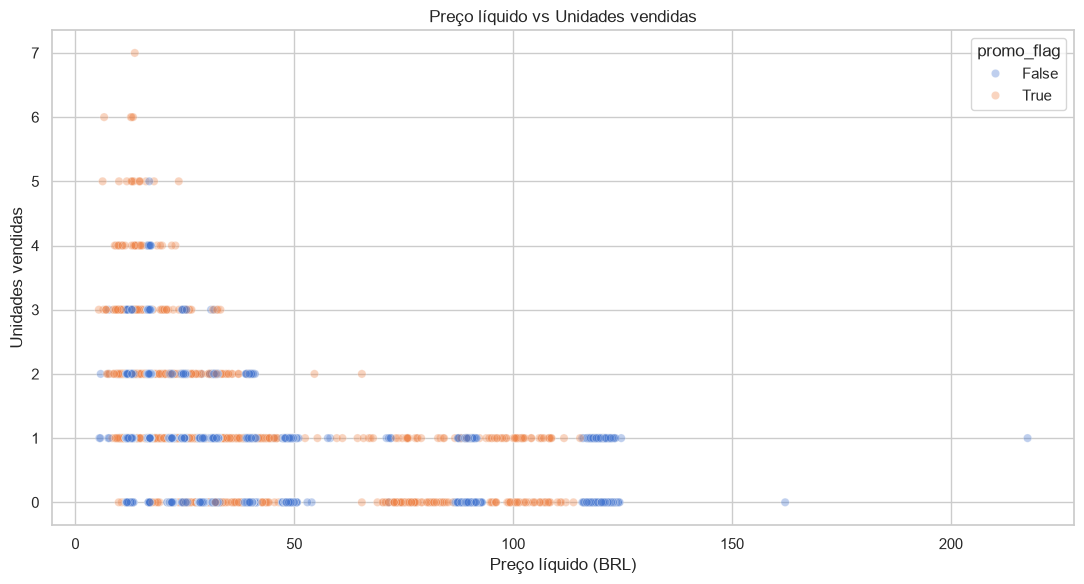

In [9]:
plot_sample = fact.sample(min(15000, len(fact)), random_state=42)

plt.figure(figsize=(11, 6))
sns.scatterplot(
    data=plot_sample,
    x="net_unit_price_brl",
    y="units_sold",
    hue="promo_flag",
    alpha=0.35,
)
plt.title("Preço líquido vs Unidades vendidas")
plt.xlabel("Preço líquido (BRL)")
plt.ylabel("Unidades vendidas")
plt.tight_layout()
plt.show()

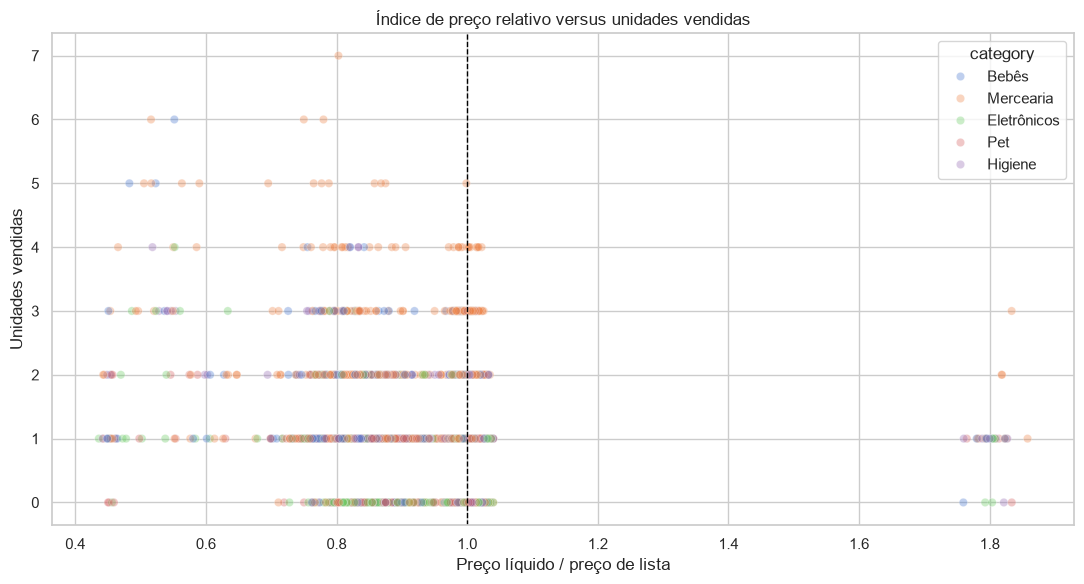

In [10]:
plt.figure(figsize=(11, 6))
sns.scatterplot(
    data=plot_sample,
    x="relative_price_index",
    y="units_sold",
    hue="category",
    alpha=0.35,
)
plt.axvline(1.0, color="black", linestyle="--", linewidth=1)
plt.title("Índice de preço relativo versus unidades vendidas")
plt.xlabel("Preço líquido / preço de lista")
plt.ylabel("Unidades vendidas")
plt.tight_layout()
plt.show()

## Preparação Variaveis p/ Elasticidade

In [11]:
elasticity_data = fact.loc[
    (~fact["anomaly_flag"]) &
    (fact["units_sold"] > 0) &
    (fact["net_unit_price_brl"] > 0)
].copy()

elasticity_data["log_units"] = np.log(elasticity_data["units_sold"])
elasticity_data["log_price"] = np.log(elasticity_data["net_unit_price_brl"])
elasticity_data["log_discount_factor"] = np.log1p(elasticity_data["discount_pct"])

## Elasticidade global com regressão log-log

In [12]:
global_model = LinearRegression()

X_global = elasticity_data[["log_price"]]
y_global = elasticity_data["log_units"]

global_model.fit(X_global, y_global)

global_elasticity = float(global_model.coef_[0])
global_intercept = float(global_model.intercept_)
global_r2 = float(global_model.score(X_global, y_global))

print("Elasticidade global:", global_elasticity)
print("R²:", global_r2)

Elasticidade global: -0.17877665309197985
R²: 0.0897813852764986


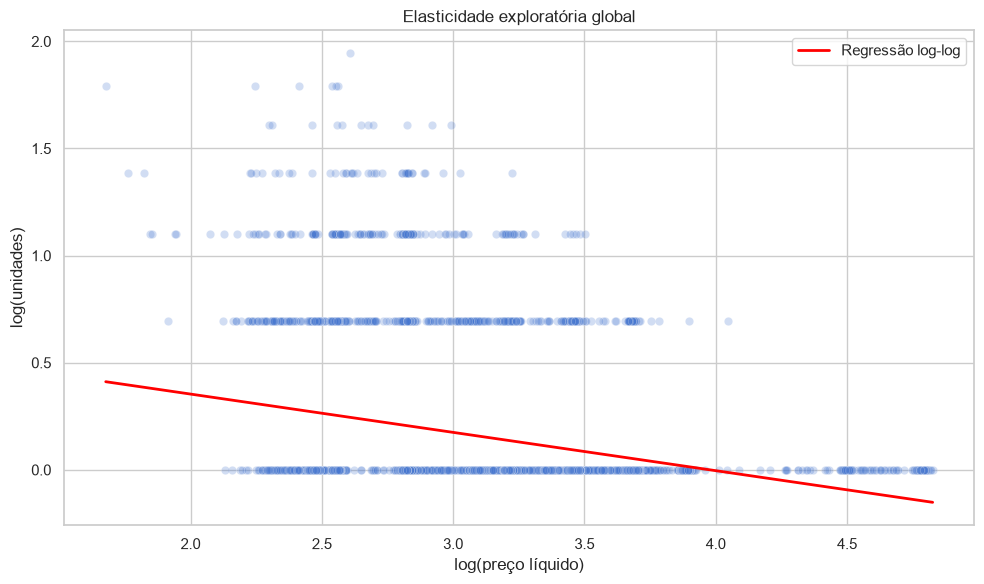

In [13]:
elasticity_data["pred_log_units"] = global_model.predict(
    elasticity_data[["log_price"]]
)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=elasticity_data.sample(min(10000, len(elasticity_data)), random_state=42),
    x="log_price",
    y="log_units",
    alpha=0.25,
)
plot_x = np.linspace(
    elasticity_data["log_price"].min(),
    elasticity_data["log_price"].max(),
    100,
)
plot_y = global_intercept + global_elasticity * plot_x
plt.plot(plot_x, plot_y, color="red", linewidth=2, label="Regressão log-log")
plt.title("Elasticidade exploratória global")
plt.xlabel("log(preço líquido)")
plt.ylabel("log(unidades)")
plt.legend()
plt.tight_layout()
plt.show()

## Elasticidade por produto

In [14]:
def estimate_product_elasticity(group):
    result = {
        "observations": len(group),
        "price_std": group["net_unit_price_brl"].std(),
        "elasticity": np.nan,
        "r2": np.nan,
        "status": "insufficient_data",
    }

    if len(group) < 30:
        return pd.Series(result)

    if group["net_unit_price_brl"].nunique() < 5:
        return pd.Series(result)

    model = LinearRegression()
    X = group[["log_price"]]
    y = group["log_units"]
    model.fit(X, y)

    result["elasticity"] = float(model.coef_[0])
    result["r2"] = float(model.score(X, y))
    result["status"] = "ok"
    return pd.Series(result)

elasticity_by_product = (
    elasticity_data
    .groupby(["product_id", "product_name", "category"])
    .apply(estimate_product_elasticity, include_groups=False)
    .reset_index()
)

elasticity_by_product.sort_values("elasticity")

,product_id,product_name,category,observations,price_std,elasticity,r2,status
1,P002,Café Tradicional 500g,Mercearia,3559,0.8812,-1.8479,0.0648,ok
0,P001,Café Premium 500g,Mercearia,3508,1.3236,-1.6796,0.1074,ok
7,P008,Lenço Umedecido 48un,Bebês,3455,0.6240,-1.6442,0.1043,ok
5,P006,Sabonete Líquido 250ml,Higiene,3483,0.6765,-1.5828,0.0842,ok
3,P004,Arroz Tipo 1 5kg,Mercearia,3183,1.7721,-1.3358,0.1551,ok
11,P012,Carregador USB-C,Eletrônicos,3044,2.3106,-1.1575,0.1706,ok
4,P005,Shampoo Hidratante 400ml,Higiene,2558,1.2935,-0.9216,0.2182,ok
9,P010,Areia Higiênica 4kg,Pet,1795,2.1365,-0.5419,0.3142,ok
6,P007,Fralda Infantil M 30un,Bebês,1632,3.4445,-0.3708,0.1906,ok
2,P003,Azeite Extra Virgem 500ml,Mercearia,1263,2.9990,-0.2878,0.1827,ok


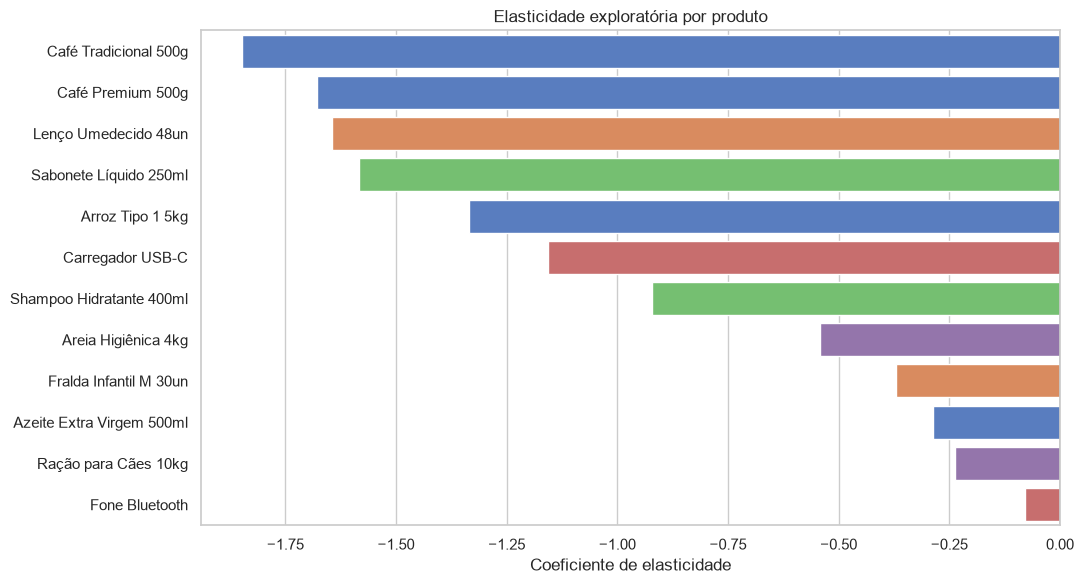

In [15]:
plt.figure(figsize=(11, 6))
sns.barplot(
    data=elasticity_by_product.sort_values("elasticity"),
    x="elasticity",
    y="product_name",
    hue="category",
    dodge=False,
    legend=False,
)
plt.axvline(0, color="black", linewidth=1)
plt.title("Elasticidade exploratória por produto")
plt.xlabel("Coeficiente de elasticidade")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [16]:
def classify_elasticity(row):
    if row["status"] != "ok":
        return "insufficient_data"
    if row["price_std"] <= 0:
        return "no_price_variation"
    if row["elasticity"] >= 0:
        return "non_negative_association"
    if row["r2"] < 0.02:
        return "weak_fit"
    return "usable_for_exploration"

elasticity_by_product["quality_flag"] = elasticity_by_product.apply(
    classify_elasticity,
    axis=1,
)

elasticity_by_product[[
    "product_id",
    "product_name",
    "elasticity",
    "r2",
    "price_std",
    "quality_flag",
]]

,product_id,product_name,elasticity,r2,price_std,quality_flag
0,P001,Café Premium 500g,-1.6796,0.1074,1.3236,usable_for_exploration
1,P002,Café Tradicional 500g,-1.8479,0.0648,0.8812,usable_for_exploration
2,P003,Azeite Extra Virgem 500ml,-0.2878,0.1827,2.9990,usable_for_exploration
3,P004,Arroz Tipo 1 5kg,-1.3358,0.1551,1.7721,usable_for_exploration
4,P005,Shampoo Hidratante 400ml,-0.9216,0.2182,1.2935,usable_for_exploration
5,P006,Sabonete Líquido 250ml,-1.5828,0.0842,0.6765,usable_for_exploration
6,P007,Fralda Infantil M 30un,-0.3708,0.1906,3.4445,usable_for_exploration
7,P008,Lenço Umedecido 48un,-1.6442,0.1043,0.6240,usable_for_exploration
8,P009,Ração para Cães 10kg,-0.2381,0.1996,10.7869,usable_for_exploration
9,P010,Areia Higiênica 4kg,-0.5419,0.3142,2.1365,usable_for_exploration


## Elasticidade com controles de calendário e promoção

In [17]:
control_data = fact.loc[
    (~fact["anomaly_flag"]) &
    (fact["units_sold"] > 0) &
    (fact["net_unit_price_brl"] > 0)
].copy()

control_data["log_units"] = np.log(control_data["units_sold"])
control_data["log_price"] = np.log(control_data["net_unit_price_brl"])
control_data["promo_int"] = control_data["promo_flag"].astype(int)
control_data["weekend_int"] = control_data["is_weekend"].astype(int)
control_data["holiday_int"] = control_data["is_holiday"].astype(int)

In [18]:
control_features = [
    "log_price",
    "promo_int",
    "weekend_int",
    "holiday_int",
    "trend_index",
    "discount_pct",
]

control_categorical = ["product_id", "region_id"]

X_control = pd.get_dummies(
    control_data[control_features + control_categorical],
    columns=control_categorical,
    drop_first=True,
    dtype=float,
)
y_control = control_data["log_units"]

control_model = LinearRegression()
control_model.fit(X_control, y_control)

control_elasticity = float(
    control_model.coef_[X_control.columns.get_loc("log_price")]
)
control_r2 = float(control_model.score(X_control, y_control))

print("Elasticidade controlada:", control_elasticity)
print("R²:", control_r2)

Elasticidade controlada: -0.4053952858835962
R²: 0.4933842360711429


## Premissas da Simulação

In [20]:
simulation_assumptions = {
    "elasticity_source": "elasticity_by_product",
    "demand_cap_by_stock": True,
    "use_anomaly_rows": False,
    "base_period": "validation_without_known_anomalies",
    "scenario_unit": "daily_product_region",
    "inventory_risk_threshold": 0.80,
    "deep_discount_warning": 0.35,
    "max_price_change": 0.30,
    "min_price_change": -0.30,
}

simulation_assumptions

{'elasticity_source': 'elasticity_by_product',
 'demand_cap_by_stock': True,
 'use_anomaly_rows': False,
 'base_period': 'validation_without_known_anomalies',
 'scenario_unit': 'daily_product_region',
 'inventory_risk_threshold': 0.8,
 'deep_discount_warning': 0.35,
 'max_price_change': 0.3,
 'min_price_change': -0.3}

## Construção Parametros por Produto

In [21]:
elasticity_lookup = elasticity_by_product[
    ["product_id", "elasticity", "quality_flag"]
].copy()

# Fallback apenas para simulação exploratória de produtos sem coeficiente confiável.
DEFAULT_ELASTICITY = -1.20

elasticity_lookup["elasticity_used"] = np.where(
    elasticity_lookup["quality_flag"] == "usable_for_exploration",
    elasticity_lookup["elasticity"],
    DEFAULT_ELASTICITY,
)

elasticity_lookup

,product_id,elasticity,quality_flag,elasticity_used
0,P001,-1.6796,usable_for_exploration,-1.6796
1,P002,-1.8479,usable_for_exploration,-1.8479
2,P003,-0.2878,usable_for_exploration,-0.2878
3,P004,-1.3358,usable_for_exploration,-1.3358
4,P005,-0.9216,usable_for_exploration,-0.9216
5,P006,-1.5828,usable_for_exploration,-1.5828
6,P007,-0.3708,usable_for_exploration,-0.3708
7,P008,-1.6442,usable_for_exploration,-1.6442
8,P009,-0.2381,usable_for_exploration,-0.2381
9,P010,-0.5419,usable_for_exploration,-0.5419


In [22]:
scenario_base = base_segment.merge(
    elasticity_lookup[["product_id", "elasticity_used", "quality_flag"]],
    on="product_id",
    how="left",
)

scenario_base.head()

,product_id,product_name,category,region_id,region_name,base_units_sold,base_median_units,base_price_brl,base_list_price_brl,base_discount_pct,unit_cost_brl,base_stock_units,base_stockout_rate,base_revenue_brl,base_margin_brl,elasticity_used,quality_flag
0,P001,Café Premium 500g,Mercearia,R01,Sudeste,1.7697,2.0000,24.6692,24.9000,0.0093,12.8000,2.1629,0.1067,43.5098,20.8581,-1.6796,usable_for_exploration
1,P001,Café Premium 500g,Mercearia,R02,Sul,1.2778,1.0000,24.6469,24.9000,0.0101,13.0700,1.6389,0.0667,30.9969,14.2964,-1.6796,usable_for_exploration
2,P001,Café Premium 500g,Mercearia,R03,Nordeste,1.1341,1.0000,24.4807,24.9000,0.0163,13.6000,1.4302,0.1006,27.4491,12.0256,-1.6796,usable_for_exploration
3,P001,Café Premium 500g,Mercearia,R04,Centro-Oeste,1.0393,1.0000,24.5313,24.9000,0.0137,13.4600,1.1461,0.0393,25.2490,11.2597,-1.6796,usable_for_exploration
4,P001,Café Premium 500g,Mercearia,R05,Norte,0.8674,1.0000,24.7178,24.9000,0.0067,13.9900,0.9724,0.0221,21.4290,9.2940,-1.6796,usable_for_exploration


In [23]:
assert scenario_base["elasticity_used"].notna().all()

## Cenários de preço e desconto

In [24]:
price_changes = [-0.20, -0.10, 0.00, 0.10, 0.20]
discount_changes = [0.00, 0.05, 0.10, 0.20]

scenario_grid = pd.DataFrame(
    [
        {
            "scenario_id": f"P{int(price_change * 100):+03d}_D{int(discount_change * 100):02d}",
            "price_change_pct": price_change,
            "additional_discount_pct": discount_change,
        }
        for price_change in price_changes
        for discount_change in discount_changes
    ]
)

scenario_grid

,scenario_id,price_change_pct,additional_discount_pct
0,P-20_D00,-0.2000,0.0000
1,P-20_D05,-0.2000,0.0500
2,P-20_D10,-0.2000,0.1000
3,P-20_D20,-0.2000,0.2000
4,P-10_D00,-0.1000,0.0000
5,P-10_D05,-0.1000,0.0500
6,P-10_D10,-0.1000,0.1000
7,P-10_D20,-0.1000,0.2000
8,P+00_D00,0.0000,0.0000
9,P+00_D05,0.0000,0.0500


## Função de simulação

In [26]:
def simulate_scenario(base_frame, scenario_row, elasticity_column="elasticity_used"):
    sim = base_frame.copy()

    price_change = float(scenario_row["price_change_pct"])
    additional_discount = float(scenario_row["additional_discount_pct"])
    scenario_id = scenario_row["scenario_id"]

    # Preço líquido simulado antes do limite de estoque.
    sim["scenario_price_brl"] = (
        sim["base_price_brl"] * (1.0 + price_change)
    )
    sim["scenario_price_brl"] = sim["scenario_price_brl"] * (
        1.0 - additional_discount
    )

    sim["scenario_price_change_pct"] = (
        sim["scenario_price_brl"] / sim["base_price_brl"] - 1.0
    )
    sim["scenario_discount_pct"] = (
        sim["base_discount_pct"] + additional_discount
    ).clip(0, 0.90)

    # Relação log-log: Q_scenario = Q_base * (P_scenario/P_base)^elasticidade.
    price_ratio = (
        sim["scenario_price_brl"] / sim["base_price_brl"]
    ).clip(lower=0.01)
    sim["potential_units"] = sim["base_units_sold"] * (
        price_ratio ** sim[elasticity_column]
    )
    sim["potential_units"] = sim["potential_units"].clip(lower=0)

    # Estoque limita a venda efetivamente atendida.
    sim["scenario_units_sold"] = np.minimum(
        sim["potential_units"],
        sim["base_stock_units"],
    )

    sim["scenario_revenue_brl"] = (
        sim["scenario_units_sold"] * sim["scenario_price_brl"]
    )
    sim["scenario_margin_brl"] = (
        sim["scenario_revenue_brl"] -
        sim["scenario_units_sold"] * sim["unit_cost_brl"]
    )
    sim["scenario_margin_pct"] = np.where(
        sim["scenario_revenue_brl"] > 0,
        sim["scenario_margin_brl"] / sim["scenario_revenue_brl"],
        0.0,
    )

    sim["lost_sales_units"] = (
        sim["potential_units"] - sim["scenario_units_sold"]
    ).clip(lower=0)
    sim["stockout_risk_flag"] = (
        sim["potential_units"] > sim["base_stock_units"]
    )
    sim["stock_coverage_ratio"] = np.where(
        sim["potential_units"] > 0,
        sim["base_stock_units"] / sim["potential_units"],
        np.inf,
    )
    sim["scenario_id"] = scenario_id
    sim["deep_discount_warning"] = (
        sim["scenario_discount_pct"] >= 0.35
    )

    # Variações contra o cenário-base.
    sim["revenue_delta_brl"] = (
        sim["scenario_revenue_brl"] - sim["base_revenue_brl"]
    )
    sim["margin_delta_brl"] = (
        sim["scenario_margin_brl"] - sim["base_margin_brl"]
    )
    sim["units_delta"] = (
        sim["scenario_units_sold"] - sim["base_units_sold"]
    )

    return sim

## Simulação completa

In [28]:
all_scenarios = []

for _, scenario_row in scenario_grid.iterrows():
    scenario_result = simulate_scenario(
        scenario_base,
        scenario_row,
    )
    all_scenarios.append(scenario_result)

scenarios = pd.concat(all_scenarios, ignore_index=True)

print(f"Linhas simuladas: {len(scenarios):,}")
scenarios.head()

Linhas simuladas: 1,200


,product_id,product_name,category,region_id,region_name,base_units_sold,base_median_units,base_price_brl,base_list_price_brl,base_discount_pct,unit_cost_brl,base_stock_units,base_stockout_rate,base_revenue_brl,base_margin_brl,elasticity_used,quality_flag,scenario_price_brl,scenario_price_change_pct,scenario_discount_pct,potential_units,scenario_units_sold,scenario_revenue_brl,scenario_margin_brl,scenario_margin_pct,lost_sales_units,stockout_risk_flag,stock_coverage_ratio,scenario_id,deep_discount_warning,revenue_delta_brl,margin_delta_brl,units_delta
0,P001,Café Premium 500g,Mercearia,R01,Sudeste,1.7697,2.0000,24.6692,24.9000,0.0093,12.8000,2.1629,0.1067,43.5098,20.8581,-1.6796,usable_for_exploration,19.7353,-0.2000,0.0093,2.5743,2.1629,42.6860,15.0006,0.3514,0.4114,True,0.8402,P-20_D00,False,-0.8238,-5.8575,0.3933
1,P001,Café Premium 500g,Mercearia,R02,Sul,1.2778,1.0000,24.6469,24.9000,0.0101,13.0700,1.6389,0.0667,30.9969,14.2964,-1.6796,usable_for_exploration,19.7176,-0.2000,0.0101,1.8588,1.6389,32.3149,10.8946,0.3371,0.2199,True,0.8817,P-20_D00,False,1.3179,-3.4018,0.3611
2,P001,Café Premium 500g,Mercearia,R03,Nordeste,1.1341,1.0000,24.4807,24.9000,0.0163,13.6000,1.4302,0.1006,27.4491,12.0256,-1.6796,usable_for_exploration,19.5846,-0.2000,0.0163,1.6497,1.4302,28.0092,8.5590,0.3056,0.2196,True,0.8669,P-20_D00,False,0.5602,-3.4666,0.2961
3,P001,Café Premium 500g,Mercearia,R04,Centro-Oeste,1.0393,1.0000,24.5313,24.9000,0.0137,13.4600,1.1461,0.0393,25.2490,11.2597,-1.6796,usable_for_exploration,19.6251,-0.2000,0.0137,1.5119,1.1461,22.4917,7.0656,0.3141,0.3658,True,0.7580,P-20_D00,False,-2.7574,-4.1941,0.1067
4,P001,Café Premium 500g,Mercearia,R05,Norte,0.8674,1.0000,24.7178,24.9000,0.0067,13.9900,0.9724,0.0221,21.4290,9.2940,-1.6796,usable_for_exploration,19.7742,-0.2000,0.0067,1.2618,0.9724,19.2280,5.6244,0.2925,0.2894,True,0.7706,P-20_D00,False,-2.2010,-3.6696,0.1050


## Agregação de Cenarios

In [29]:
scenario_summary = (
    scenarios
    .merge(
        scenario_grid[["scenario_id", "price_change_pct", "additional_discount_pct"]],
        on="scenario_id",
        how="left",
    )
    .groupby(
        [
            "scenario_id",
            "price_change_pct",
            "additional_discount_pct",
        ],
        as_index=False,
    )
    .agg(
        base_units=("base_units_sold", "sum"),
        potential_units=("potential_units", "sum"),
        scenario_units=("scenario_units_sold", "sum"),
        base_revenue_brl=("base_revenue_brl", "sum"),
        scenario_revenue_brl=("scenario_revenue_brl", "sum"),
        base_margin_brl=("base_margin_brl", "sum"),
        scenario_margin_brl=("scenario_margin_brl", "sum"),
        lost_sales_units=("lost_sales_units", "sum"),
        stockout_risk_rate=("stockout_risk_flag", "mean"),
        warning_rate=("deep_discount_warning", "mean"),
    )
)

scenario_summary["revenue_delta_brl"] = (
    scenario_summary["scenario_revenue_brl"] -
    scenario_summary["base_revenue_brl"]
)
scenario_summary["margin_delta_brl"] = (
    scenario_summary["scenario_margin_brl"] -
    scenario_summary["base_margin_brl"]
)
scenario_summary["units_delta"] = (
    scenario_summary["scenario_units"] -
    scenario_summary["base_units"]
)
scenario_summary["scenario_margin_pct"] = np.where(
    scenario_summary["scenario_revenue_brl"] > 0,
    scenario_summary["scenario_margin_brl"] /
    scenario_summary["scenario_revenue_brl"],
    0.0,
)

scenario_summary.sort_values("scenario_margin_brl", ascending=False).head(10)

,scenario_id,price_change_pct,additional_discount_pct,base_units,potential_units,scenario_units,base_revenue_brl,scenario_revenue_brl,base_margin_brl,scenario_margin_brl,lost_sales_units,stockout_risk_rate,warning_rate,revenue_delta_brl,margin_delta_brl,units_delta,scenario_margin_pct
8,P+20_D00,0.2000,0.0000,46.7645,36.7247,36.7247,"1,189.4919","1,182.5587",552.6788,656.8525,0.0000,0.0000,0.0000,-6.9332,104.1737,-10.0398,0.5555
9,P+20_D05,0.2000,0.0500,46.7645,39.2746,39.2746,"1,189.4919","1,186.8150",552.6788,632.6152,0.0000,0.0000,0.0000,-2.6769,79.9365,-7.4899,0.5330
4,P+10_D00,0.1000,0.0000,46.7645,41.1708,41.1708,"1,189.4919","1,190.4124",552.6788,615.1547,0.0000,0.0000,0.0000,0.9205,62.4759,-5.5937,0.5168
10,P+20_D10,0.2000,0.1000,46.7645,42.1855,42.1855,"1,189.4919","1,192.4632",552.6788,605.9781,0.0000,0.0000,0.0000,2.9713,53.2994,-4.5789,0.5082
5,P+10_D05,0.1000,0.0500,46.7645,44.0801,44.0801,"1,189.4919","1,196.4918",552.6788,589.1199,0.0000,0.0000,0.0000,6.9999,36.4411,-2.6844,0.4924
0,P+00_D00,0.0000,0.0000,46.7645,46.7645,46.7645,"1,189.4919","1,202.5714",552.6788,565.7582,0.0000,0.0000,0.0000,13.0795,13.0795,0.0000,0.4705
6,P+10_D10,0.1000,0.1000,46.7645,47.4032,47.4032,"1,189.4919","1,204.0717",552.6788,560.2791,0.0000,0.0000,0.0000,14.5798,7.6003,0.6387,0.4653
11,P+20_D20,0.2000,0.2000,46.7645,49.4208,49.4208,"1,189.4919","1,208.9260",552.6788,543.1427,0.0000,0.0000,0.0000,19.4341,-9.5360,2.6564,0.4493
1,P+00_D05,0.0000,0.0500,46.7645,50.1294,50.1294,"1,189.4919","1,210.6676",552.6788,537.1820,0.0000,0.0000,0.0000,21.1757,-15.4967,3.3650,0.4437
2,P+00_D10,0.0000,0.1000,46.7645,53.9753,53.5180,"1,189.4919","1,213.3477",552.6788,502.2505,0.4573,0.1000,0.0000,23.8558,-50.4283,6.7535,0.4139


## Ranking por receita, margem e risco

In [30]:
scenario_summary.sort_values(
    "scenario_revenue_brl",
    ascending=False,
).head(10)[[
    "scenario_id",
    "price_change_pct",
    "additional_discount_pct",
    "scenario_revenue_brl",
    "scenario_margin_brl",
    "stockout_risk_rate",
]]

,scenario_id,price_change_pct,additional_discount_pct,scenario_revenue_brl,scenario_margin_brl,stockout_risk_rate
2,P+00_D10,0.0000,0.1000,"1,213.3477",502.2505,0.1000
12,P-10_D00,-0.1000,0.0000,"1,213.3477",502.2505,0.1000
7,P+10_D20,0.1000,0.2000,"1,210.9089",485.6237,0.2000
1,P+00_D05,0.0000,0.0500,"1,210.6676",537.1820,0.0000
11,P+20_D20,0.2000,0.2000,"1,208.9260",543.1427,0.0000
6,P+10_D10,0.1000,0.1000,"1,204.0717",560.2791,0.0000
0,P+00_D00,0.0000,0.0000,"1,202.5714",565.7582,0.0000
13,P-10_D05,-0.1000,0.0500,"1,198.6781",460.1440,0.2833
5,P+10_D05,0.1000,0.0500,"1,196.4918",589.1199,0.0000
10,P+20_D10,0.2000,0.1000,"1,192.4632",605.9781,0.0000


In [31]:
scenario_summary.sort_values(
    "scenario_margin_brl",
    ascending=False,
).head(10)[[
    "scenario_id",
    "price_change_pct",
    "additional_discount_pct",
    "scenario_revenue_brl",
    "scenario_margin_brl",
    "stockout_risk_rate",
]]

,scenario_id,price_change_pct,additional_discount_pct,scenario_revenue_brl,scenario_margin_brl,stockout_risk_rate
8,P+20_D00,0.2000,0.0000,"1,182.5587",656.8525,0.0000
9,P+20_D05,0.2000,0.0500,"1,186.8150",632.6152,0.0000
4,P+10_D00,0.1000,0.0000,"1,190.4124",615.1547,0.0000
10,P+20_D10,0.2000,0.1000,"1,192.4632",605.9781,0.0000
5,P+10_D05,0.1000,0.0500,"1,196.4918",589.1199,0.0000
0,P+00_D00,0.0000,0.0000,"1,202.5714",565.7582,0.0000
6,P+10_D10,0.1000,0.1000,"1,204.0717",560.2791,0.0000
11,P+20_D20,0.2000,0.2000,"1,208.9260",543.1427,0.0000
1,P+00_D05,0.0000,0.0500,"1,210.6676",537.1820,0.0000
2,P+00_D10,0.0000,0.1000,"1,213.3477",502.2505,0.1000


In [32]:
scenario_summary.sort_values(
    ["stockout_risk_rate", "scenario_margin_brl"],
    ascending=[True, False],
).head(10)[[
    "scenario_id",
    "price_change_pct",
    "additional_discount_pct",
    "scenario_revenue_brl",
    "scenario_margin_brl",
    "stockout_risk_rate",
]]

,scenario_id,price_change_pct,additional_discount_pct,scenario_revenue_brl,scenario_margin_brl,stockout_risk_rate
8,P+20_D00,0.2000,0.0000,"1,182.5587",656.8525,0.0000
9,P+20_D05,0.2000,0.0500,"1,186.8150",632.6152,0.0000
4,P+10_D00,0.1000,0.0000,"1,190.4124",615.1547,0.0000
10,P+20_D10,0.2000,0.1000,"1,192.4632",605.9781,0.0000
5,P+10_D05,0.1000,0.0500,"1,196.4918",589.1199,0.0000
0,P+00_D00,0.0000,0.0000,"1,202.5714",565.7582,0.0000
6,P+10_D10,0.1000,0.1000,"1,204.0717",560.2791,0.0000
11,P+20_D20,0.2000,0.2000,"1,208.9260",543.1427,0.0000
1,P+00_D05,0.0000,0.0500,"1,210.6676",537.1820,0.0000
2,P+00_D10,0.0000,0.1000,"1,213.3477",502.2505,0.1000


## Regra de risco explícita

In [33]:
RISK_THRESHOLD = 0.20
MAX_DISCOUNT = 0.35

scenario_summary["risk_status"] = np.select(
    [
        scenario_summary["stockout_risk_rate"] > RISK_THRESHOLD,
        scenario_summary["additional_discount_pct"] >= MAX_DISCOUNT,
    ],
    [
        "high_stockout_risk",
        "deep_discount",
    ],
    default="within_assumptions",
)

scenario_summary["acceptable_for_review"] = (
    (scenario_summary["stockout_risk_rate"] <= RISK_THRESHOLD) &
    (scenario_summary["additional_discount_pct"] < MAX_DISCOUNT)
)

scenario_summary["acceptable_for_review"].value_counts()

acceptable_for_review
True     12
False     8
Name: count, dtype: int64

In [34]:
candidate_scenarios = scenario_summary.loc[
    scenario_summary["acceptable_for_review"]
].sort_values(
    "scenario_margin_brl",
    ascending=False,
)

candidate_scenarios.head(10)

,scenario_id,price_change_pct,additional_discount_pct,base_units,potential_units,scenario_units,base_revenue_brl,scenario_revenue_brl,base_margin_brl,scenario_margin_brl,lost_sales_units,stockout_risk_rate,warning_rate,revenue_delta_brl,margin_delta_brl,units_delta,scenario_margin_pct,risk_status,acceptable_for_review
8,P+20_D00,0.2000,0.0000,46.7645,36.7247,36.7247,"1,189.4919","1,182.5587",552.6788,656.8525,0.0000,0.0000,0.0000,-6.9332,104.1737,-10.0398,0.5555,within_assumptions,True
9,P+20_D05,0.2000,0.0500,46.7645,39.2746,39.2746,"1,189.4919","1,186.8150",552.6788,632.6152,0.0000,0.0000,0.0000,-2.6769,79.9365,-7.4899,0.5330,within_assumptions,True
4,P+10_D00,0.1000,0.0000,46.7645,41.1708,41.1708,"1,189.4919","1,190.4124",552.6788,615.1547,0.0000,0.0000,0.0000,0.9205,62.4759,-5.5937,0.5168,within_assumptions,True
10,P+20_D10,0.2000,0.1000,46.7645,42.1855,42.1855,"1,189.4919","1,192.4632",552.6788,605.9781,0.0000,0.0000,0.0000,2.9713,53.2994,-4.5789,0.5082,within_assumptions,True
5,P+10_D05,0.1000,0.0500,46.7645,44.0801,44.0801,"1,189.4919","1,196.4918",552.6788,589.1199,0.0000,0.0000,0.0000,6.9999,36.4411,-2.6844,0.4924,within_assumptions,True
0,P+00_D00,0.0000,0.0000,46.7645,46.7645,46.7645,"1,189.4919","1,202.5714",552.6788,565.7582,0.0000,0.0000,0.0000,13.0795,13.0795,0.0000,0.4705,within_assumptions,True
6,P+10_D10,0.1000,0.1000,46.7645,47.4032,47.4032,"1,189.4919","1,204.0717",552.6788,560.2791,0.0000,0.0000,0.0000,14.5798,7.6003,0.6387,0.4653,within_assumptions,True
11,P+20_D20,0.2000,0.2000,46.7645,49.4208,49.4208,"1,189.4919","1,208.9260",552.6788,543.1427,0.0000,0.0000,0.0000,19.4341,-9.5360,2.6564,0.4493,within_assumptions,True
1,P+00_D05,0.0000,0.0500,46.7645,50.1294,50.1294,"1,189.4919","1,210.6676",552.6788,537.1820,0.0000,0.0000,0.0000,21.1757,-15.4967,3.3650,0.4437,within_assumptions,True
2,P+00_D10,0.0000,0.1000,46.7645,53.9753,53.5180,"1,189.4919","1,213.3477",552.6788,502.2505,0.4573,0.1000,0.0000,23.8558,-50.4283,6.7535,0.4139,within_assumptions,True


## Fronteira de Pareto

In [35]:
def is_dominated(row, candidates):
    others = candidates[candidates["scenario_id"] != row["scenario_id"]]

    better_or_equal = (
        (others["scenario_revenue_brl"] >= row["scenario_revenue_brl"]) &
        (others["scenario_margin_brl"] >= row["scenario_margin_brl"]) &
        (others["stockout_risk_rate"] <= row["stockout_risk_rate"])
    )

    strictly_better = (
        (others["scenario_revenue_brl"] > row["scenario_revenue_brl"]) |
        (others["scenario_margin_brl"] > row["scenario_margin_brl"]) |
        (others["stockout_risk_rate"] < row["stockout_risk_rate"])
    )

    return bool((better_or_equal & strictly_better).any())

pareto_input = scenario_summary.loc[
    scenario_summary["acceptable_for_review"]
].copy()

pareto_input["dominated"] = pareto_input.apply(
    is_dominated,
    candidates=pareto_input,
    axis=1,
)

pareto_frontier = pareto_input.loc[~pareto_input["dominated"]].copy()
pareto_frontier.sort_values("scenario_margin_brl", ascending=False)

,scenario_id,price_change_pct,additional_discount_pct,base_units,potential_units,scenario_units,base_revenue_brl,scenario_revenue_brl,base_margin_brl,scenario_margin_brl,lost_sales_units,stockout_risk_rate,warning_rate,revenue_delta_brl,margin_delta_brl,units_delta,scenario_margin_pct,risk_status,acceptable_for_review,dominated
8,P+20_D00,0.2000,0.0000,46.7645,36.7247,36.7247,"1,189.4919","1,182.5587",552.6788,656.8525,0.0000,0.0000,0.0000,-6.9332,104.1737,-10.0398,0.5555,within_assumptions,True,False
9,P+20_D05,0.2000,0.0500,46.7645,39.2746,39.2746,"1,189.4919","1,186.8150",552.6788,632.6152,0.0000,0.0000,0.0000,-2.6769,79.9365,-7.4899,0.5330,within_assumptions,True,False
4,P+10_D00,0.1000,0.0000,46.7645,41.1708,41.1708,"1,189.4919","1,190.4124",552.6788,615.1547,0.0000,0.0000,0.0000,0.9205,62.4759,-5.5937,0.5168,within_assumptions,True,False
10,P+20_D10,0.2000,0.1000,46.7645,42.1855,42.1855,"1,189.4919","1,192.4632",552.6788,605.9781,0.0000,0.0000,0.0000,2.9713,53.2994,-4.5789,0.5082,within_assumptions,True,False
5,P+10_D05,0.1000,0.0500,46.7645,44.0801,44.0801,"1,189.4919","1,196.4918",552.6788,589.1199,0.0000,0.0000,0.0000,6.9999,36.4411,-2.6844,0.4924,within_assumptions,True,False
0,P+00_D00,0.0000,0.0000,46.7645,46.7645,46.7645,"1,189.4919","1,202.5714",552.6788,565.7582,0.0000,0.0000,0.0000,13.0795,13.0795,0.0000,0.4705,within_assumptions,True,False
6,P+10_D10,0.1000,0.1000,46.7645,47.4032,47.4032,"1,189.4919","1,204.0717",552.6788,560.2791,0.0000,0.0000,0.0000,14.5798,7.6003,0.6387,0.4653,within_assumptions,True,False
11,P+20_D20,0.2000,0.2000,46.7645,49.4208,49.4208,"1,189.4919","1,208.9260",552.6788,543.1427,0.0000,0.0000,0.0000,19.4341,-9.5360,2.6564,0.4493,within_assumptions,True,False
1,P+00_D05,0.0000,0.0500,46.7645,50.1294,50.1294,"1,189.4919","1,210.6676",552.6788,537.1820,0.0000,0.0000,0.0000,21.1757,-15.4967,3.3650,0.4437,within_assumptions,True,False
2,P+00_D10,0.0000,0.1000,46.7645,53.9753,53.5180,"1,189.4919","1,213.3477",552.6788,502.2505,0.4573,0.1000,0.0000,23.8558,-50.4283,6.7535,0.4139,within_assumptions,True,False


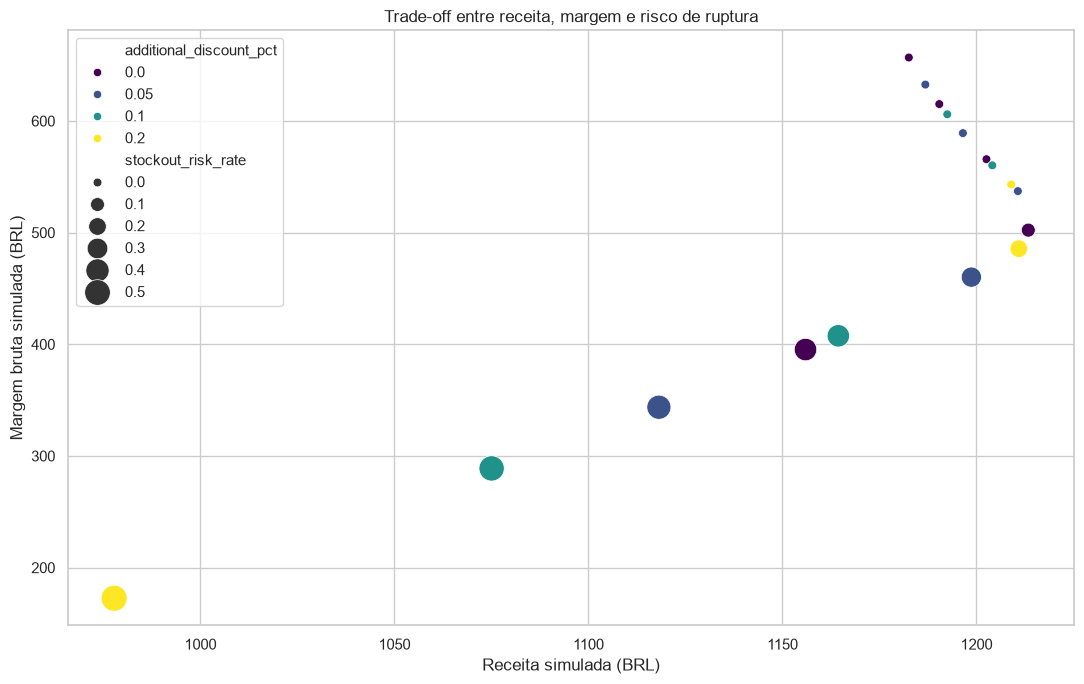

In [36]:
plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=scenario_summary,
    x="scenario_revenue_brl",
    y="scenario_margin_brl",
    size="stockout_risk_rate",
    hue="additional_discount_pct",
    palette="viridis",
    sizes=(40, 350),
)

plt.title("Trade-off entre receita, margem e risco de ruptura")
plt.xlabel("Receita simulada (BRL)")
plt.ylabel("Margem bruta simulada (BRL)")
plt.tight_layout()
plt.show()

## Heatmap

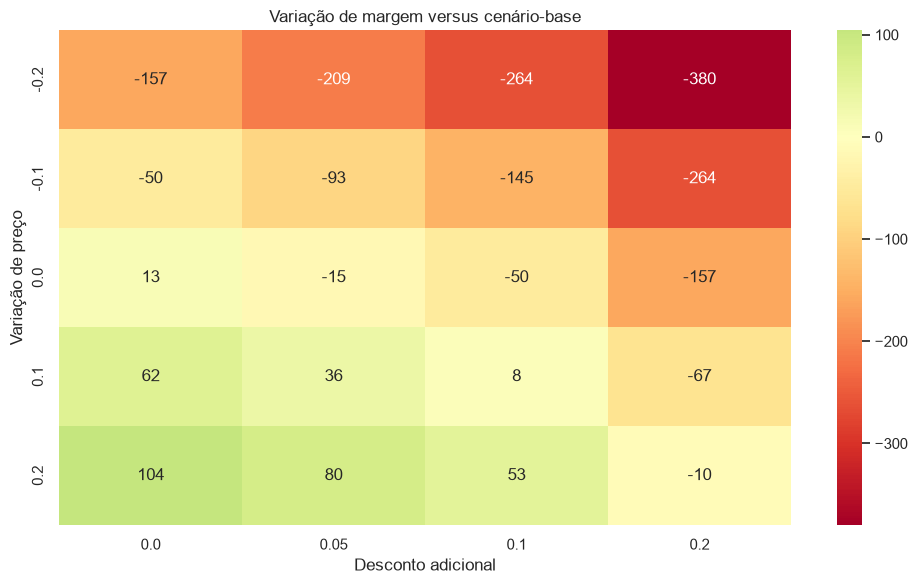

In [37]:
margin_pivot = scenario_summary.pivot_table(
    index="price_change_pct",
    columns="additional_discount_pct",
    values="margin_delta_brl",
    aggfunc="mean",
)

plt.figure(figsize=(10, 6))
sns.heatmap(margin_pivot, annot=True, fmt=",.0f", cmap="RdYlGn", center=0)
plt.title("Variação de margem versus cenário-base")
plt.xlabel("Desconto adicional")
plt.ylabel("Variação de preço")
plt.tight_layout()
plt.show()

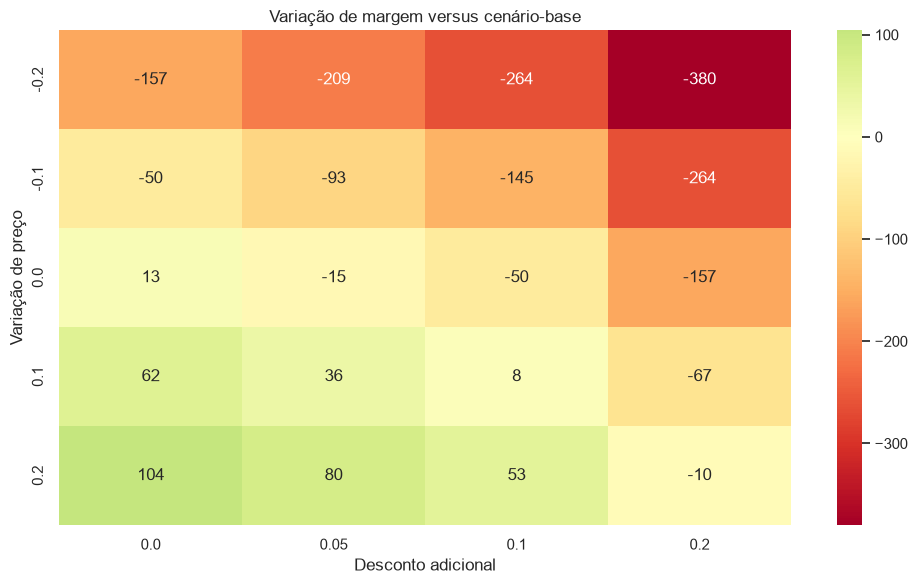

In [38]:
margin_pivot = scenario_summary.pivot_table(
    index="price_change_pct",
    columns="additional_discount_pct",
    values="margin_delta_brl",
    aggfunc="mean",
)

plt.figure(figsize=(10, 6))
sns.heatmap(margin_pivot, annot=True, fmt=",.0f", cmap="RdYlGn", center=0)
plt.title("Variação de margem versus cenário-base")
plt.xlabel("Desconto adicional")
plt.ylabel("Variação de preço")
plt.tight_layout()
plt.show()

## Análise por produto

In [39]:
product_scenario_summary = (
    scenarios
    .merge(
        scenario_grid[["scenario_id", "price_change_pct", "additional_discount_pct"]],
        on="scenario_id",
        how="left",
    )
    .groupby(
        [
            "product_id",
            "product_name",
            "scenario_id",
            "price_change_pct",
            "additional_discount_pct",
        ],
        as_index=False,
    )
    .agg(
        base_units=("base_units_sold", "sum"),
        potential_units=("potential_units", "sum"),
        scenario_units=("scenario_units_sold", "sum"),
        base_revenue_brl=("base_revenue_brl", "sum"),
        scenario_revenue_brl=("scenario_revenue_brl", "sum"),
        base_margin_brl=("base_margin_brl", "sum"),
        scenario_margin_brl=("scenario_margin_brl", "sum"),
        lost_sales_units=("lost_sales_units", "sum"),
        stockout_risk_rate=("stockout_risk_flag", "mean"),
    )
)

product_scenario_summary["margin_delta_brl"] = (
    product_scenario_summary["scenario_margin_brl"] -
    product_scenario_summary["base_margin_brl"]
)

product_scenario_summary.head()

,product_id,product_name,scenario_id,price_change_pct,additional_discount_pct,base_units,potential_units,scenario_units,base_revenue_brl,scenario_revenue_brl,base_margin_brl,scenario_margin_brl,lost_sales_units,stockout_risk_rate,margin_delta_brl
0,P001,Café Premium 500g,P+00_D00,0.0000,0.0000,6.0882,6.0882,6.0882,148.6338,149.8488,67.7338,68.9488,0.0000,0.0000,1.2150
1,P001,Café Premium 500g,P+00_D05,0.0000,0.0500,6.0882,6.6360,6.6360,148.6338,155.1648,67.7338,66.9859,0.0000,0.0000,-0.7480
2,P001,Café Premium 500g,P+00_D10,0.0000,0.1000,6.0882,7.2669,7.1095,148.6338,157.4865,67.7338,63.0771,0.1574,0.4000,-4.6567
3,P001,Café Premium 500g,P+00_D20,0.0000,0.2000,6.0882,8.8566,7.3504,148.6338,144.7297,67.7338,47.1442,1.5061,1.0000,-20.5897
4,P001,Café Premium 500g,P+10_D00,0.1000,0.0000,6.0882,5.1876,5.1876,148.6338,140.4499,67.7338,71.5174,0.0000,0.0000,3.7836


In [40]:
product_candidates = product_scenario_summary.loc[
    product_scenario_summary["stockout_risk_rate"] <= RISK_THRESHOLD
].copy()

best_by_product = (
    product_candidates.sort_values(
        ["product_id", "scenario_margin_brl"],
        ascending=[True, False],
    )
    .groupby("product_id", as_index=False)
    .head(1)
)

best_by_product[[
    "product_id",
    "product_name",
    "scenario_id",
    "price_change_pct",
    "additional_discount_pct",
    "scenario_revenue_brl",
    "scenario_margin_brl",
    "stockout_risk_rate",
]]

,product_id,product_name,scenario_id,price_change_pct,additional_discount_pct,scenario_revenue_brl,scenario_margin_brl,stockout_risk_rate
8,P001,Café Premium 500g,P+20_D00,0.2000,0.0000,132.3851,72.8253,0.0000
25,P002,Café Tradicional 500g,P+10_D05,0.1000,0.0500,138.6837,74.0122,0.0000
48,P003,Azeite Extra Virgem 500ml,P+20_D00,0.2000,0.0000,76.9437,41.5012,0.0000
68,P004,Arroz Tipo 1 5kg,P+20_D00,0.2000,0.0000,140.9237,71.9463,0.0000
88,P005,Shampoo Hidratante 400ml,P+20_D00,0.2000,0.0000,76.5202,45.2468,0.0000
109,P006,Sabonete Líquido 250ml,P+20_D05,0.2000,0.0500,71.9687,45.0003,0.0000
128,P007,Fralda Infantil M 30un,P+20_D00,0.2000,0.0000,116.2181,58.4112,0.0000
144,P008,Lenço Umedecido 48un,P+10_D00,0.1000,0.0000,64.7646,39.0287,0.0000
168,P009,Ração para Cães 10kg,P+20_D00,0.2000,0.0000,114.2727,55.3545,0.0000
188,P010,Areia Higiênica 4kg,P+20_D00,0.2000,0.0000,74.4386,39.2000,0.0000


## Análise de ruptura e capacidade

In [41]:
capacity_summary = scenarios.groupby("scenario_id", as_index=False).agg(
    potential_units=("potential_units", "sum"),
    scenario_units=("scenario_units_sold", "sum"),
    lost_sales_units=("lost_sales_units", "sum"),
    stockout_risk_rate=("stockout_risk_flag", "mean"),
)

capacity_summary["service_level"] = np.where(
    capacity_summary["potential_units"] > 0,
    capacity_summary["scenario_units"] /
    capacity_summary["potential_units"],
    1.0,
)

capacity_summary.sort_values("service_level")

,scenario_id,potential_units,scenario_units,lost_sales_units,stockout_risk_rate,service_level
19,P-20_D20,87.3045,60.3680,26.9365,0.5167,0.6915
15,P-10_D20,73.7391,59.3694,14.3696,0.4833,0.8051
18,P-20_D10,73.7391,59.3694,14.3696,0.4833,0.8051
17,P-20_D05,68.3028,58.6811,9.6217,0.4333,0.8591
16,P-20_D00,63.5525,57.7068,5.8458,0.3667,0.9080
3,P+00_D20,63.5525,57.7068,5.8458,0.3667,0.9080
14,P-10_D10,62.4580,57.4074,5.0506,0.3667,0.9191
13,P-10_D05,57.9325,55.9463,1.9861,0.2833,0.9657
7,P+10_D20,55.6705,54.7768,0.8937,0.2000,0.9839
12,P-10_D00,53.9753,53.5180,0.4573,0.1000,0.9915


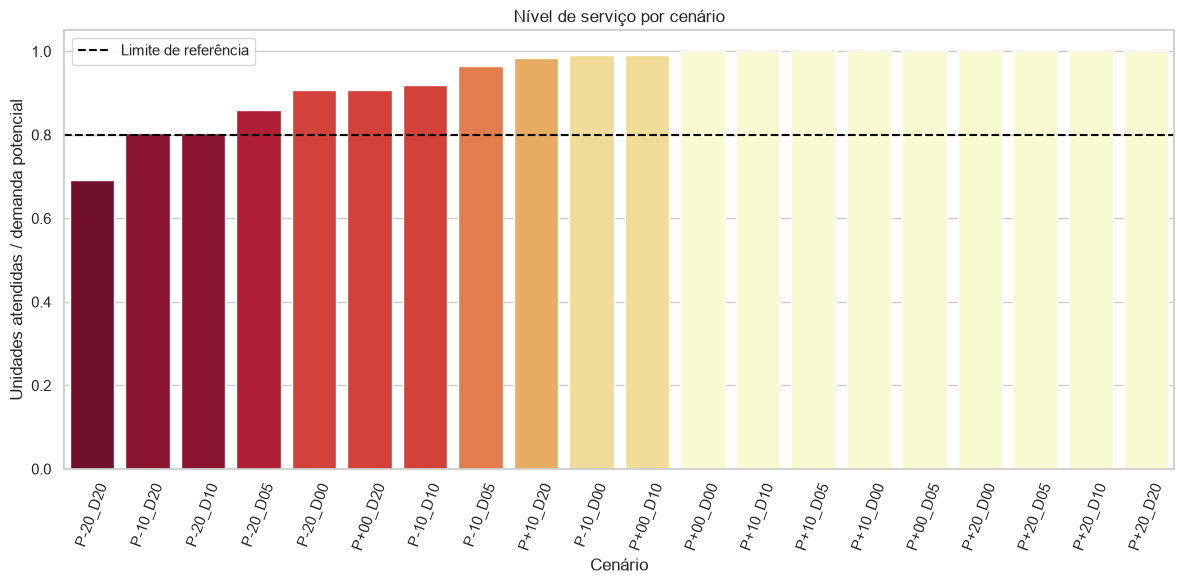

In [42]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=capacity_summary.sort_values("service_level"),
    x="scenario_id",
    y="service_level",
    hue="stockout_risk_rate",
    palette="YlOrRd",
    legend=False,
)
plt.axhline(0.80, color="black", linestyle="--", label="Limite de referência")
plt.title("Nível de serviço por cenário")
plt.xlabel("Cenário")
plt.ylabel("Unidades atendidas / demanda potencial")
plt.xticks(rotation=70)
plt.legend()
plt.tight_layout()
plt.show()

## Análise de sensibilidade à elasticidade

In [43]:
elasticity_multipliers = [0.75, 1.00, 1.25]
sensitivity_results = []

for multiplier in elasticity_multipliers:
    sensitivity_base = scenario_base.copy()
    sensitivity_base["elasticity_used"] = (
        sensitivity_base["elasticity_used"] * multiplier
    )

    for _, scenario_row in scenario_grid.iterrows():
        result = simulate_scenario(sensitivity_base, scenario_row)
        result["elasticity_multiplier"] = multiplier
        sensitivity_results.append(result)

sensitivity = pd.concat(sensitivity_results, ignore_index=True)

sensitivity_summary = (
    sensitivity.groupby(
        ["elasticity_multiplier", "scenario_id"],
        as_index=False,
    )
    .agg(
        scenario_revenue_brl=("scenario_revenue_brl", "sum"),
        scenario_margin_brl=("scenario_margin_brl", "sum"),
        stockout_risk_rate=("stockout_risk_flag", "mean"),
    )
)

sensitivity_summary.head()

,elasticity_multiplier,scenario_id,scenario_revenue_brl,scenario_margin_brl,stockout_risk_rate
0,0.7500,P+00_D00,"1,202.5714",565.7582,0.0000
1,0.7500,P+00_D05,"1,193.1425",529.0738,0.0000
2,0.7500,P+00_D10,"1,181.4138",488.3926,0.0833
3,0.7500,P+00_D20,"1,127.7126",385.2630,0.3000
4,0.7500,P+10_D00,"1,221.8724",631.9796,0.0000


In [44]:
sensitivity_summary.sort_values(
    ["scenario_id", "elasticity_multiplier"]
).head(20)

,elasticity_multiplier,scenario_id,scenario_revenue_brl,scenario_margin_brl,stockout_risk_rate
0,0.7500,P+00_D00,"1,202.5714",565.7582,0.0000
20,1.0000,P+00_D00,"1,202.5714",565.7582,0.0000
40,1.2500,P+00_D00,"1,202.5714",565.7582,0.0000
1,0.7500,P+00_D05,"1,193.1425",529.0738,0.0000
21,1.0000,P+00_D05,"1,210.6676",537.1820,0.0000
41,1.2500,P+00_D05,"1,227.8761",545.1329,0.0500
2,0.7500,P+00_D10,"1,181.4138",488.3926,0.0833
22,1.0000,P+00_D10,"1,213.3477",502.2505,0.1000
42,1.2500,P+00_D10,"1,241.8724",514.6284,0.2000
3,0.7500,P+00_D20,"1,127.7126",385.2630,0.3000


## Validações de consistência

In [45]:
assert (scenarios["scenario_price_brl"] > 0).all()
assert (scenarios["potential_units"] >= 0).all()
assert (scenarios["scenario_units_sold"] >= 0).all()
assert (scenarios["scenario_revenue_brl"] >= 0).all()
assert (scenarios["scenario_units_sold"] <= scenarios["potential_units"] + 1e-9).all()
assert np.isfinite(scenarios["scenario_margin_brl"]).all()
assert np.isfinite(scenarios["scenario_margin_pct"]).all()

# Reconciliações econômicas.
assert np.isclose(
    scenarios["scenario_revenue_brl"],
    scenarios["scenario_units_sold"] * scenarios["scenario_price_brl"],
    atol=0.01,
).all()

assert np.isclose(
    scenarios["scenario_margin_brl"],
    scenarios["scenario_revenue_brl"] -
    scenarios["scenario_units_sold"] * scenarios["unit_cost_brl"],
    atol=0.01,
).all()

print("Validações de pricing aprovadas")

Validações de pricing aprovadas


In [46]:
print("Maior desconto:", scenarios["scenario_discount_pct"].max())
print("Menor preço:", scenarios["scenario_price_brl"].min())
print("Maior risco por cenário:", scenario_summary["stockout_risk_rate"].max())

Maior desconto: 0.22025055555555556
Menor preço: 7.515937078651686
Maior risco por cenário: 0.5166666666666667


## Export de resultados








In [47]:
OUTPUT_DIR = REPORT_DIR / "trilha_c"
OUTPUT_DIR.mkdir(exist_ok=True)

scenarios.to_parquet(
    OUTPUT_DIR / "pricing_scenarios_detail.parquet",
    index=False,
)
scenarios.to_csv(
    OUTPUT_DIR / "pricing_scenarios_detail.csv",
    index=False,
)

scenario_summary.to_csv(
    OUTPUT_DIR / "pricing_scenarios_summary.csv",
    index=False,
)
product_scenario_summary.to_csv(
    OUTPUT_DIR / "pricing_scenarios_by_product.csv",
    index=False,
)
elasticity_by_product.to_csv(
    OUTPUT_DIR / "elasticity_by_product.csv",
    index=False,
)
sensitivity_summary.to_csv(
    OUTPUT_DIR / "elasticity_sensitivity.csv",
    index=False,
)

with open(OUTPUT_DIR / "simulation_assumptions.json", "w", encoding="utf-8") as file:
    json.dump(simulation_assumptions, file, ensure_ascii=False, indent=2)

## Tabela de decisões para revisão

In [48]:
review_table = scenario_summary[[
    "scenario_id",
    "price_change_pct",
    "additional_discount_pct",
    "scenario_revenue_brl",
    "scenario_margin_brl",
    "scenario_margin_pct",
    "revenue_delta_brl",
    "margin_delta_brl",
    "potential_units",
    "scenario_units",
    "lost_sales_units",
    "stockout_risk_rate",
    "risk_status",
    "acceptable_for_review",
]].sort_values(
    "scenario_margin_brl",
    ascending=False,
)

review_table.to_csv(
    OUTPUT_DIR / "pricing_review_table.csv",
    index=False,
)

review_table.head(15)

,scenario_id,price_change_pct,additional_discount_pct,scenario_revenue_brl,scenario_margin_brl,scenario_margin_pct,revenue_delta_brl,margin_delta_brl,potential_units,scenario_units,lost_sales_units,stockout_risk_rate,risk_status,acceptable_for_review
8,P+20_D00,0.2000,0.0000,"1,182.5587",656.8525,0.5555,-6.9332,104.1737,36.7247,36.7247,0.0000,0.0000,within_assumptions,True
9,P+20_D05,0.2000,0.0500,"1,186.8150",632.6152,0.5330,-2.6769,79.9365,39.2746,39.2746,0.0000,0.0000,within_assumptions,True
4,P+10_D00,0.1000,0.0000,"1,190.4124",615.1547,0.5168,0.9205,62.4759,41.1708,41.1708,0.0000,0.0000,within_assumptions,True
10,P+20_D10,0.2000,0.1000,"1,192.4632",605.9781,0.5082,2.9713,53.2994,42.1855,42.1855,0.0000,0.0000,within_assumptions,True
5,P+10_D05,0.1000,0.0500,"1,196.4918",589.1199,0.4924,6.9999,36.4411,44.0801,44.0801,0.0000,0.0000,within_assumptions,True
0,P+00_D00,0.0000,0.0000,"1,202.5714",565.7582,0.4705,13.0795,13.0795,46.7645,46.7645,0.0000,0.0000,within_assumptions,True
6,P+10_D10,0.1000,0.1000,"1,204.0717",560.2791,0.4653,14.5798,7.6003,47.4032,47.4032,0.0000,0.0000,within_assumptions,True
11,P+20_D20,0.2000,0.2000,"1,208.9260",543.1427,0.4493,19.4341,-9.5360,49.4208,49.4208,0.0000,0.0000,within_assumptions,True
1,P+00_D05,0.0000,0.0500,"1,210.6676",537.1820,0.4437,21.1757,-15.4967,50.1294,50.1294,0.0000,0.0000,within_assumptions,True
2,P+00_D10,0.0000,0.1000,"1,213.3477",502.2505,0.4139,23.8558,-50.4283,53.9753,53.5180,0.4573,0.1000,within_assumptions,True


## Integração Forecast Trilha B

In [49]:
forecast = pd.read_parquet(
    REPORT_DIR / "trilha_b" / "predictions_test.parquet"
)

In [50]:
forecast_base = (
    forecast.groupby(["product_id", "region_id"], as_index=False)
    .agg(
        base_units_sold=("prediction", "mean"),
    )
)

In [51]:
scenario_base_forecast = scenario_base.drop(
    columns=["base_units_sold"],
).merge(
    forecast_base,
    on=["product_id", "region_id"],
    how="left",
)

## Simulação Intervalos de Demanda

In [52]:
uncertainty_factors = [0.80, 1.00, 1.20]
uncertainty_results = []

for factor in uncertainty_factors:
    uncertainty_base = scenario_base.copy()
    uncertainty_base["base_units_sold"] = (
        uncertainty_base["base_units_sold"] * factor
    )

    for _, scenario_row in scenario_grid.iterrows():
        result = simulate_scenario(uncertainty_base, scenario_row)
        result["demand_factor"] = factor
        uncertainty_results.append(result)

uncertainty = pd.concat(uncertainty_results, ignore_index=True)